In [2]:
from pathlib import Path
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [3]:
DATA_PATH = Path("../data/raw")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

class_names = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

print(class_names)

['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


In [4]:
data = []

for split in ["train", "Val"]:

    for class_name in class_names:

        folder = DATA_PATH / split / class_name

        for image_path in (folder / "images").iterdir():

            if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
                continue

            label_path = folder / "labels" / (image_path.stem + ".txt")

            data.append({
                "split": split,
                "class": class_name,
                "image": str(image_path),
                "annotation": str(label_path)
            })

df = pd.DataFrame(data)

print(df.head())
print("Total images:", len(df))

   split   class                                         image  \
0  train  Glioma    ../data/raw/train/Glioma/images/gg (1).jpg   
1  train  Glioma  ../data/raw/train/Glioma/images/gg (103).jpg   
2  train  Glioma  ../data/raw/train/Glioma/images/gg (104).jpg   
3  train  Glioma  ../data/raw/train/Glioma/images/gg (105).jpg   
4  train  Glioma  ../data/raw/train/Glioma/images/gg (106).jpg   

                                     annotation  
0    ../data/raw/train/Glioma/labels/gg (1).txt  
1  ../data/raw/train/Glioma/labels/gg (103).txt  
2  ../data/raw/train/Glioma/labels/gg (104).txt  
3  ../data/raw/train/Glioma/labels/gg (105).txt  
4  ../data/raw/train/Glioma/labels/gg (106).txt  
Total images: 5249


In [5]:
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "Val"]

train_df, test_df = train_test_split(
    train_df,
    test_size=0.1,
    random_state=SEED,
    stratify=train_df["class"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 4263
Validation: 512
Test: 474


In [6]:
class_to_number = {
    "Glioma": 0,
    "Meningioma": 1,
    "No Tumor": 2,
    "Pituitary": 3
}

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

for table in [train_df, val_df, test_df]:
    table["label"] = table["class"].map(class_to_number)

print(train_df[["class", "label"]].head())

           class  label
1102      Glioma      0
1964  Meningioma      1
3944   Pituitary      3
2127  Meningioma      1
4574   Pituitary      3


In [7]:
OUTPUT_PATH = Path("../data/processed")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

train_df.to_csv(OUTPUT_PATH / "train.csv", index=False)
val_df.to_csv(OUTPUT_PATH / "val.csv", index=False)
test_df.to_csv(OUTPUT_PATH / "test.csv", index=False)

print("Splits saved!")

Splits saved!


In [9]:
def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image.set_shape((224, 224, 3))

    return image, label

In [10]:
def create_dataset(table):

    paths = table["image"].tolist()
    labels = table["label"].tolist()

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(load_image)

    dataset = dataset.batch(BATCH_SIZE)

    return dataset

In [12]:
train_ds = create_dataset(train_df)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Datasets ready!")

Datasets ready!


In [13]:
for images, labels in train_ds.take(1):

    print("Images:", images.shape)
    print("Labels:", labels.shape)

Images: (32, 224, 224, 3)
Labels: (32,)


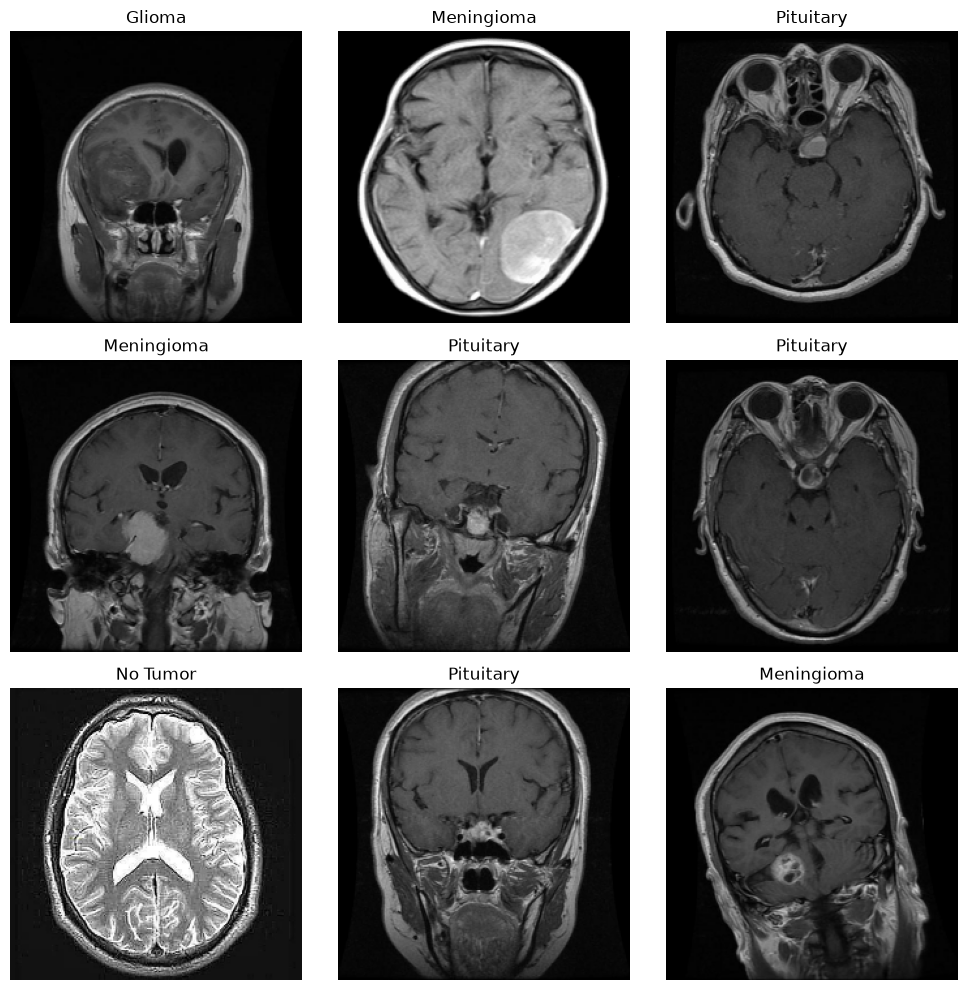

In [14]:
for images, labels in train_ds.take(1):

    plt.figure(figsize=(10, 10))

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[int(labels[i])])

        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [15]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomZoom(0.05),
    tf.keras.layers.RandomContrast(0.1)
])

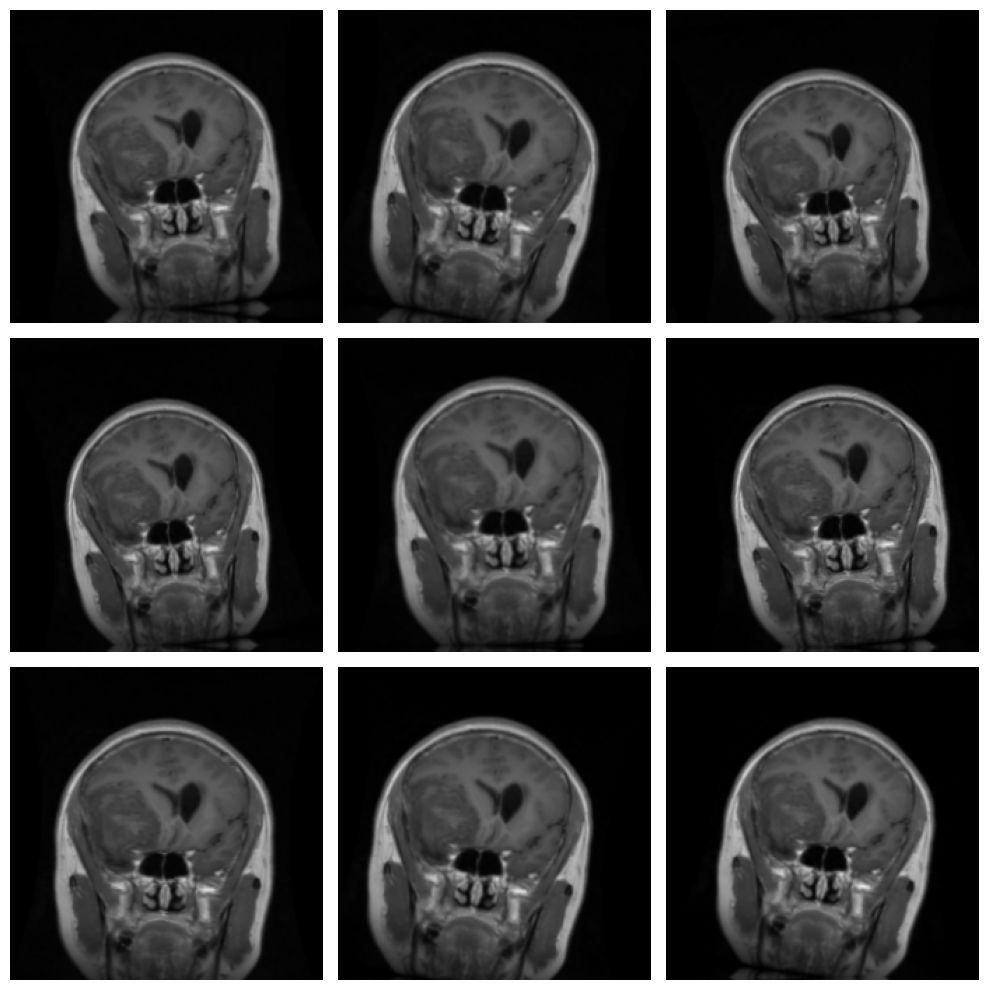

In [16]:
for images, labels in train_ds.take(1):

    image = images[0]

    plt.figure(figsize=(10, 10))

    for i in range(9):

        new_image = data_augmentation(
            tf.expand_dims(image, 0),
            training=True
        )

        plt.subplot(3, 3, i + 1)

        plt.imshow(
            tf.clip_by_value(new_image[0], 0, 255).numpy().astype("uint8")
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [17]:
print("TRAIN")
print(train_df["class"].value_counts())

print("\nVALIDATION")
print(val_df["class"].value_counts())

print("\nTEST")
print(test_df["class"].value_counts())

TRAIN
class
Meningioma    1304
Pituitary     1281
Glioma        1038
No Tumor       640
Name: count, dtype: int64

VALIDATION
class
Meningioma    140
Glioma        136
Pituitary     136
No Tumor      100
Name: count, dtype: int64

TEST
class
Meningioma    145
Pituitary     143
Glioma        115
No Tumor       71
Name: count, dtype: int64


In [18]:
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)